In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from brief_croise_1.config.conf import DATASETS
from brief_croise_1.data import download_kaggle_dataset
from brief_croise_1.analysis import detect_anomalies, get_outliers_report_Zscore, get_outliers_report_IQR, get_numerical_corr_with_target
from brief_croise_1.visualization import plot_numeric_distributions, plot_categorical_vs_target, plot_correlation_heatmap
from brief_croise_1.preprocessing import get_X_Y, split_data_stractified, preprocess_data
from brief_croise_1.models import get_models_with_params
from brief_croise_1.train import train_grid_search, summarize_grids

c:\Users\Administrator\Projects\Briefs\Brief croise - 1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
download_kaggle_dataset()

WindowsPath('C:/Users/Administrator/Projects/Briefs/Brief croise - 1/data/raw')

### LCSV loaded; shape, dtypes and a sample displayed

In [6]:
df = pd.read_csv(DATASETS['raw'])

# Etape 1

### comprendre la structure générale du jeu de données (types de données, dimensions, aperçus) ;

In [7]:
print('---------------- dataset shape -----------------')#(2000, 17)
print(df.shape )#(2000, 17)
print()
print()
print('---------- dataset colums types------------------')
print(df.dtypes)
print()
print()


---------------- dataset shape -----------------
(2000, 17)


---------- dataset colums types------------------
Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object




In [8]:
print('---------- dataset samples------------------')
df.head(5)

---------- dataset samples------------------


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


### Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes. 

In [9]:
print('---------- dataset number of unique ids ------------------')
print(df['Student_ID'].nunique())
print()
print()
print('---------- dataset number of duplicated row ------------------')
print(df.duplicated().sum())
print()
print()
print(df.drop(columns=['Student_ID']).duplicated().sum())

---------- dataset number of unique ids ------------------
2000


---------- dataset number of duplicated row ------------------
0


0


In [10]:
print('--------------- description od dataset ------------------')
display(df.describe(include='object'))
print()
print()
display(df.describe())
print()
print()
print('--------------- number of missing value columns ------------------')
print((df.isna().sum() > 0).sum()) # 7 columns
print()
print()
print('--------------- columns that have missing values ------------------')
display(list(df.columns[df.isna().sum() > 0]))
print()
print()
print('--------------- number of missing values per column ------------------')
display(df.isna().sum()) # sleep_hours 62 - GPA 38 - social_media_screen_hours 58 - diet_quality 69 - Financial_Stress 91 - Family_Support 54 - Attendance_Rate 47

--------------- description od dataset ------------------


C:\Users\Administrator\AppData\Local\Temp\ipykernel_8960\4064334531.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object'))


,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000




--------------- number of missing value columns ------------------
7


--------------- columns that have missing values ------------------


['Sleep_Hours',
 'GPA',
 'Social_Media_Hours',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Diet_Quality']



--------------- number of missing values per column ------------------


Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

### detecting the anomalies

In [11]:
detect_anomalies(df)

--------------- detecting the anomalies ------------------
social media scren time is bigger than the spent time on screen


np.int64(37)



---------- gpa that exceeds the limit --------------


np.int64(0)



---------------- sleep hours and screen time both exceed 24h -------------------


np.int64(0)



---------------- age and years of study do not match ------------------


np.int64(247)

In [12]:
IQR_res = pd.DataFrame(get_outliers_report_IQR(df))
ZSCORE_res = pd.DataFrame(get_outliers_report_Zscore(df))

display(IQR_res)
display(ZSCORE_res)

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
number_of_outliers,4.0,0.0,2.0,7.00,9.000,20.0000,7.00,0.00,0.00,12.00
percentage_of_outliers,0.2,0.0,0.1,0.35,0.450,1.0000,0.35,0.00,0.00,0.60
min_edge,15.5,-3.5,3.6,4.00,1.615,3.0125,3.95,0.15,0.75,65.75
max_edge,27.5,8.5,10.0,36.00,3.495,8.9125,13.15,11.75,12.35,104.55


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
number_of_outliers,4.0000,0.00,1.000000,4.0000,4.000000,6.000000,4.0000,0.00000,0.000000,9.000000
percentage_of_outliers,0.2000,0.00,0.050000,0.2000,0.200000,0.300000,0.2000,0.00000,0.000000,0.450000
mean,21.1315,2.63,6.758875,19.9979,2.562503,6.013955,8.5485,5.95626,6.518345,85.080236
median,21.0000,2.00,6.700000,19.8000,2.560000,6.000000,8.5000,6.10000,6.700000,85.100000


### DISTRIBUTION

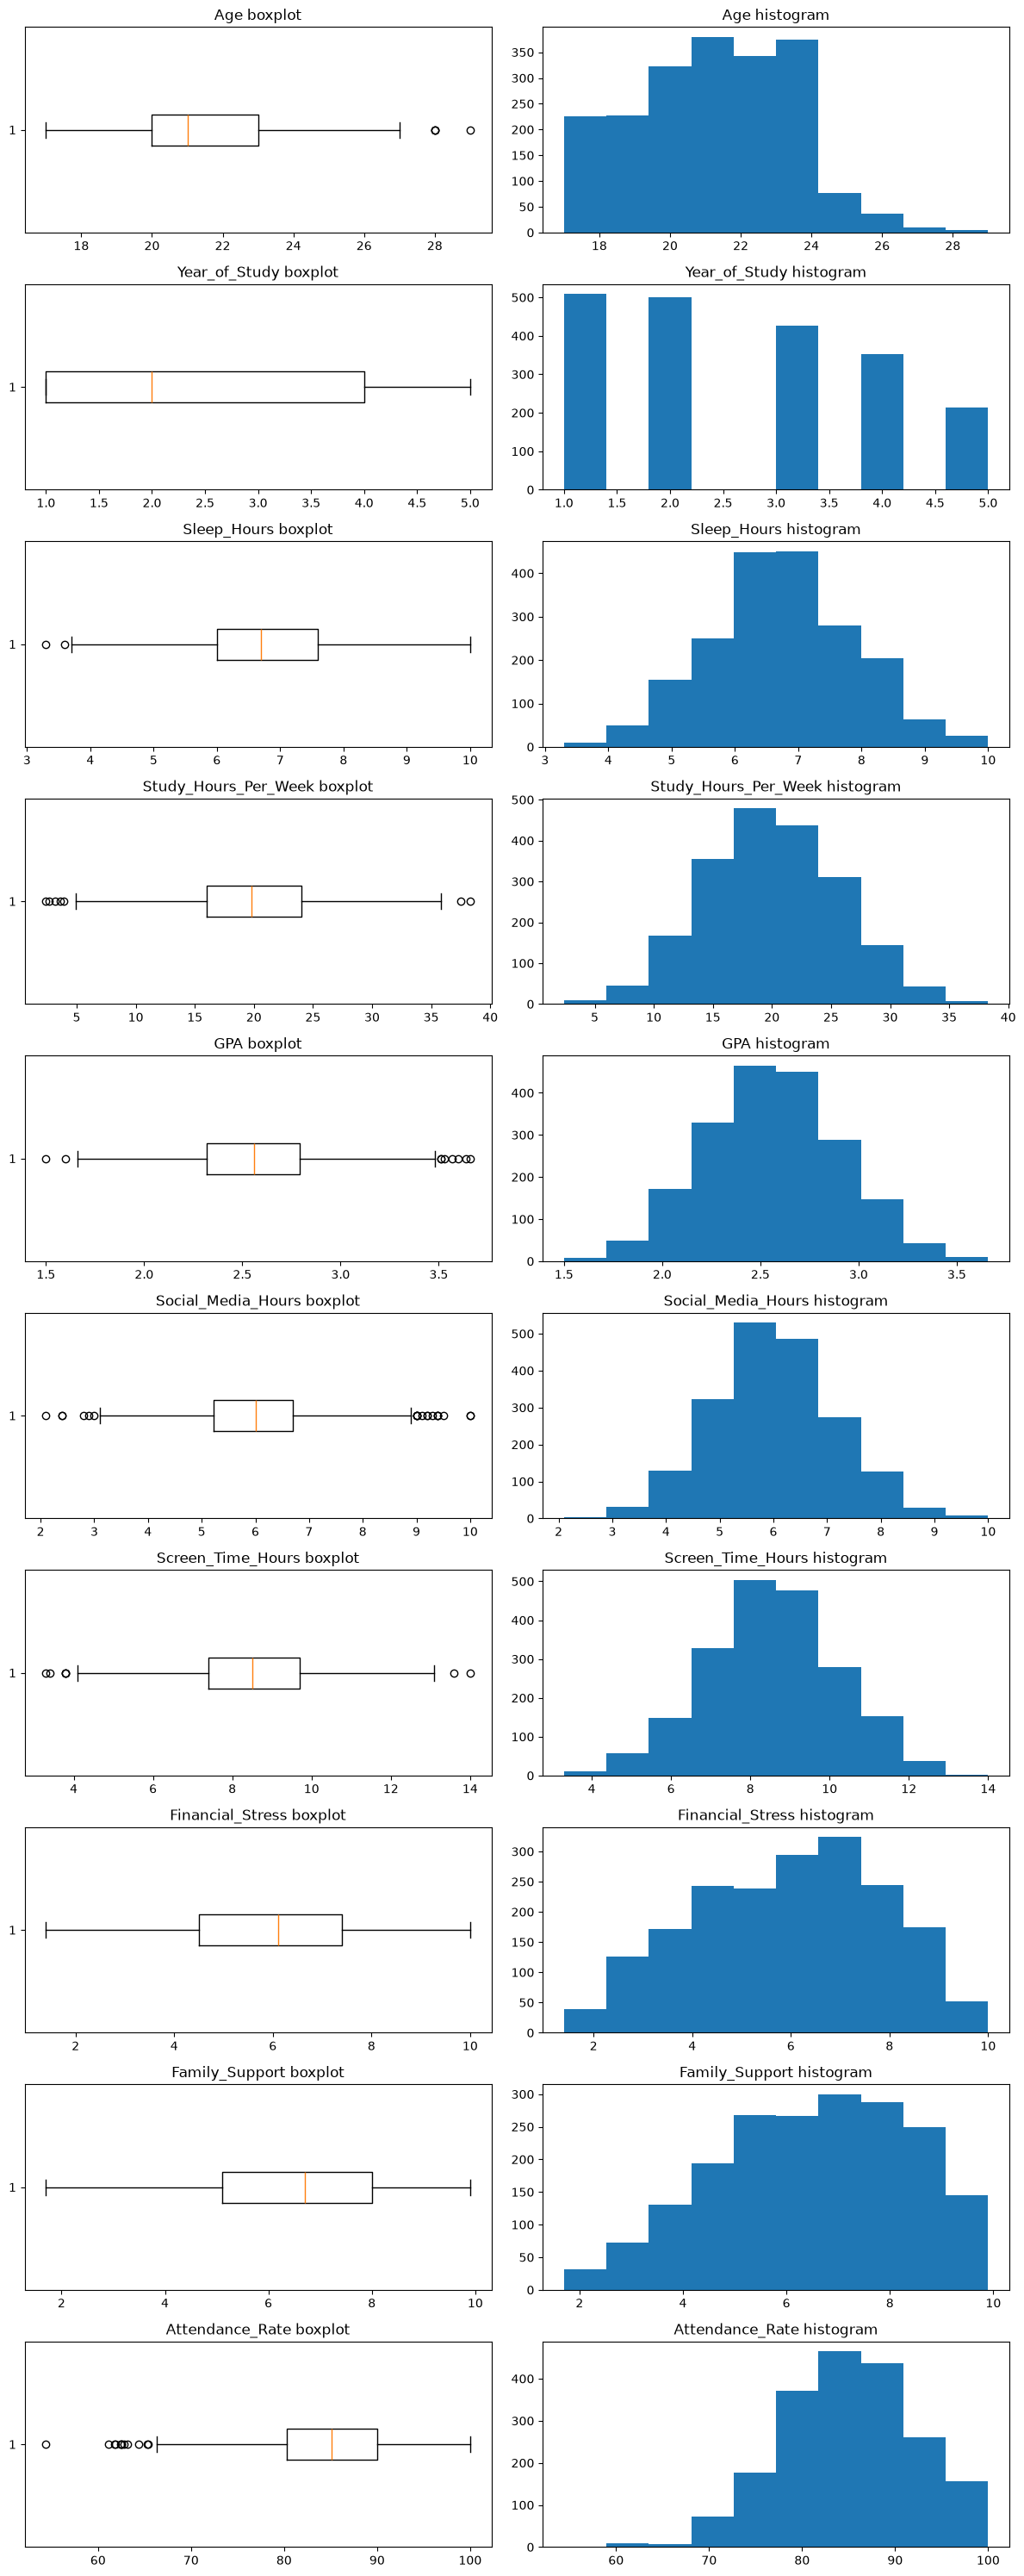

WindowsPath('C:/Users/Administrator/Projects/Briefs/Brief croise - 1/artifacts/numeric_distributions.png')

In [13]:
plot_numeric_distributions(df)

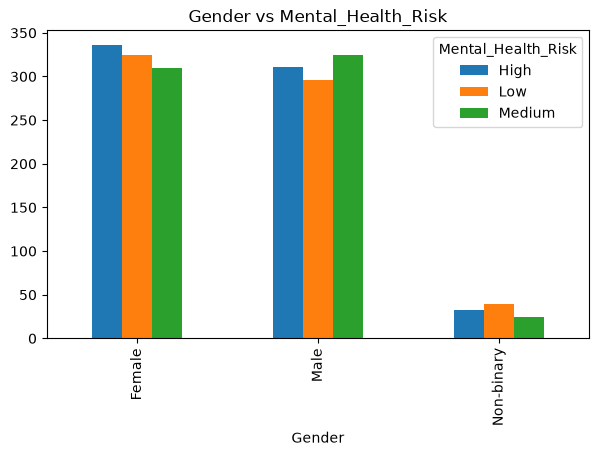

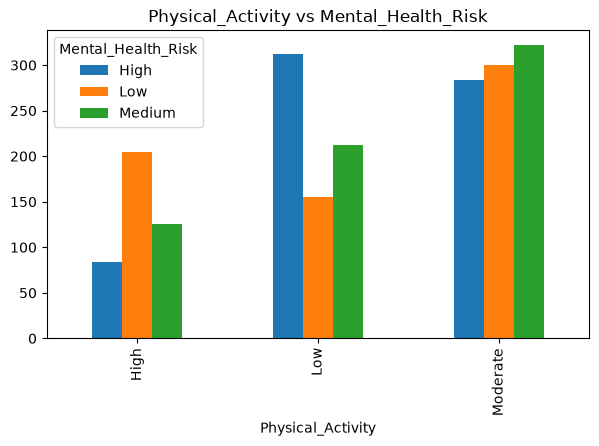

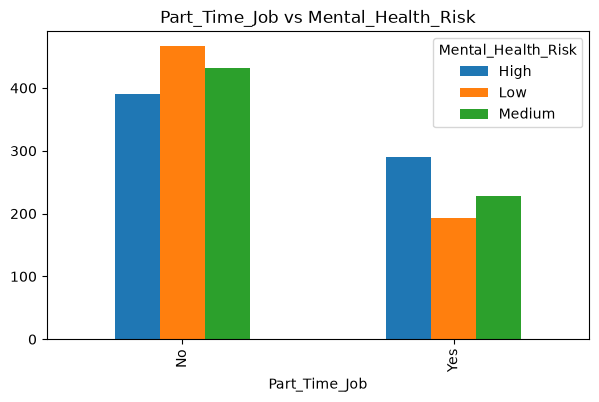

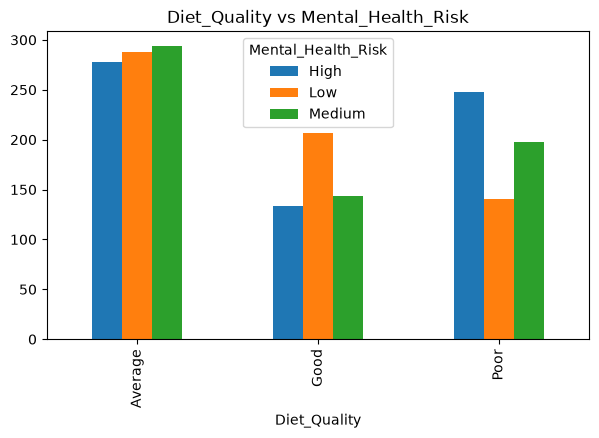

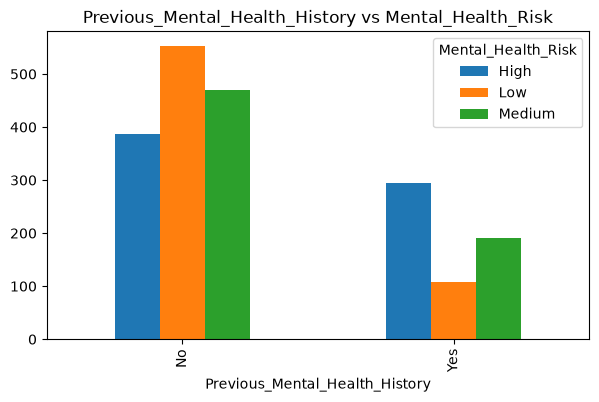

[WindowsPath('C:/Users/Administrator/Projects/Briefs/Brief croise - 1/artifacts/Gender_vs_Mental_Health_Risk.png'),
 WindowsPath('C:/Users/Administrator/Projects/Briefs/Brief croise - 1/artifacts/Physical_Activity_vs_Mental_Health_Risk.png'),
 WindowsPath('C:/Users/Administrator/Projects/Briefs/Brief croise - 1/artifacts/Part_Time_Job_vs_Mental_Health_Risk.png'),
 WindowsPath('C:/Users/Administrator/Projects/Briefs/Brief croise - 1/artifacts/Diet_Quality_vs_Mental_Health_Risk.png'),
 WindowsPath('C:/Users/Administrator/Projects/Briefs/Brief croise - 1/artifacts/Previous_Mental_Health_History_vs_Mental_Health_Risk.png')]

In [14]:
plot_categorical_vs_target(df)

### Analyser les relations entre les variables explicatives et la cible.


In [15]:
columns = df.select_dtypes(include='number').columns
skewness = pd.Series([df[col].skew() for col in columns], index=columns)
display(skewness)
display(df['Mental_Health_Risk'].value_counts()) # data is almost perfect no resampling is needed


Age                     0.200876
Year_of_Study           0.314226
Sleep_Hours             0.051094
Study_Hours_Per_Week    0.039271
GPA                     0.087445
Social_Media_Hours      0.092598
Screen_Time_Hours      -0.044073
Financial_Stress       -0.168759
Family_Support         -0.304270
Attendance_Rate        -0.116483
dtype: float64

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

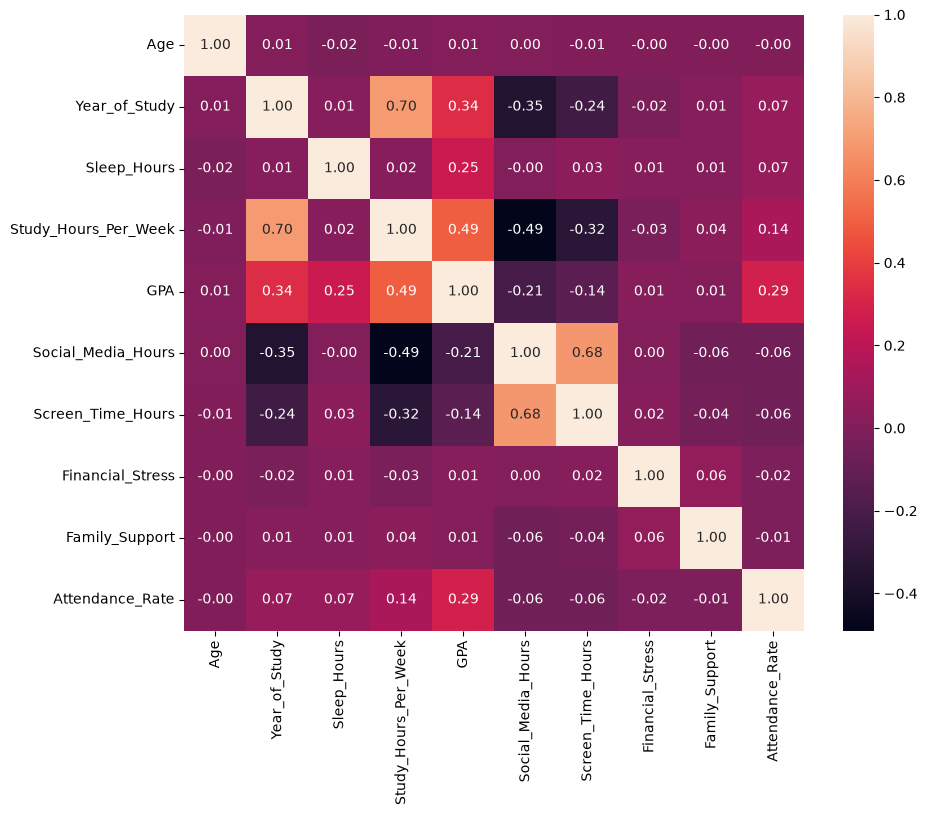

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
Age,1.000000,0.008815,-0.021858,-0.009743,0.008358,0.001142,-0.005140,-0.004355,-0.003423,-0.003486
Year_of_Study,0.008815,1.000000,0.012284,0.696491,0.342083,-0.351515,-0.236254,-0.019205,0.010676,0.069445
Sleep_Hours,-0.021858,0.012284,1.000000,0.022152,0.250487,-0.000869,0.031097,0.014863,0.012122,0.074173
Study_Hours_Per_Week,-0.009743,0.696491,0.022152,1.000000,0.494048,-0.490009,-0.323539,-0.025990,0.038001,0.135601
GPA,0.008358,0.342083,0.250487,0.494048,1.000000,-0.209415,-0.137751,0.014006,0.010097,0.286375
Social_Media_Hours,0.001142,-0.351515,-0.000869,-0.490009,-0.209415,1.000000,0.682704,0.003548,-0.056487,-0.056284
Screen_Time_Hours,-0.005140,-0.236254,0.031097,-0.323539,-0.137751,0.682704,1.000000,0.016165,-0.044761,-0.064401
Financial_Stress,-0.004355,-0.019205,0.014863,-0.025990,0.014006,0.003548,0.016165,1.000000,0.062817,-0.015682
Family_Support,-0.003423,0.010676,0.012122,0.038001,0.010097,-0.056487,-0.044761,0.062817,1.000000,-0.013561
Attendance_Rate,-0.003486,0.069445,0.074173,0.135601,0.286375,-0.056284,-0.064401,-0.015682,-0.013561,1.000000


In [16]:
correlation = plot_correlation_heatmap(df)
correlation

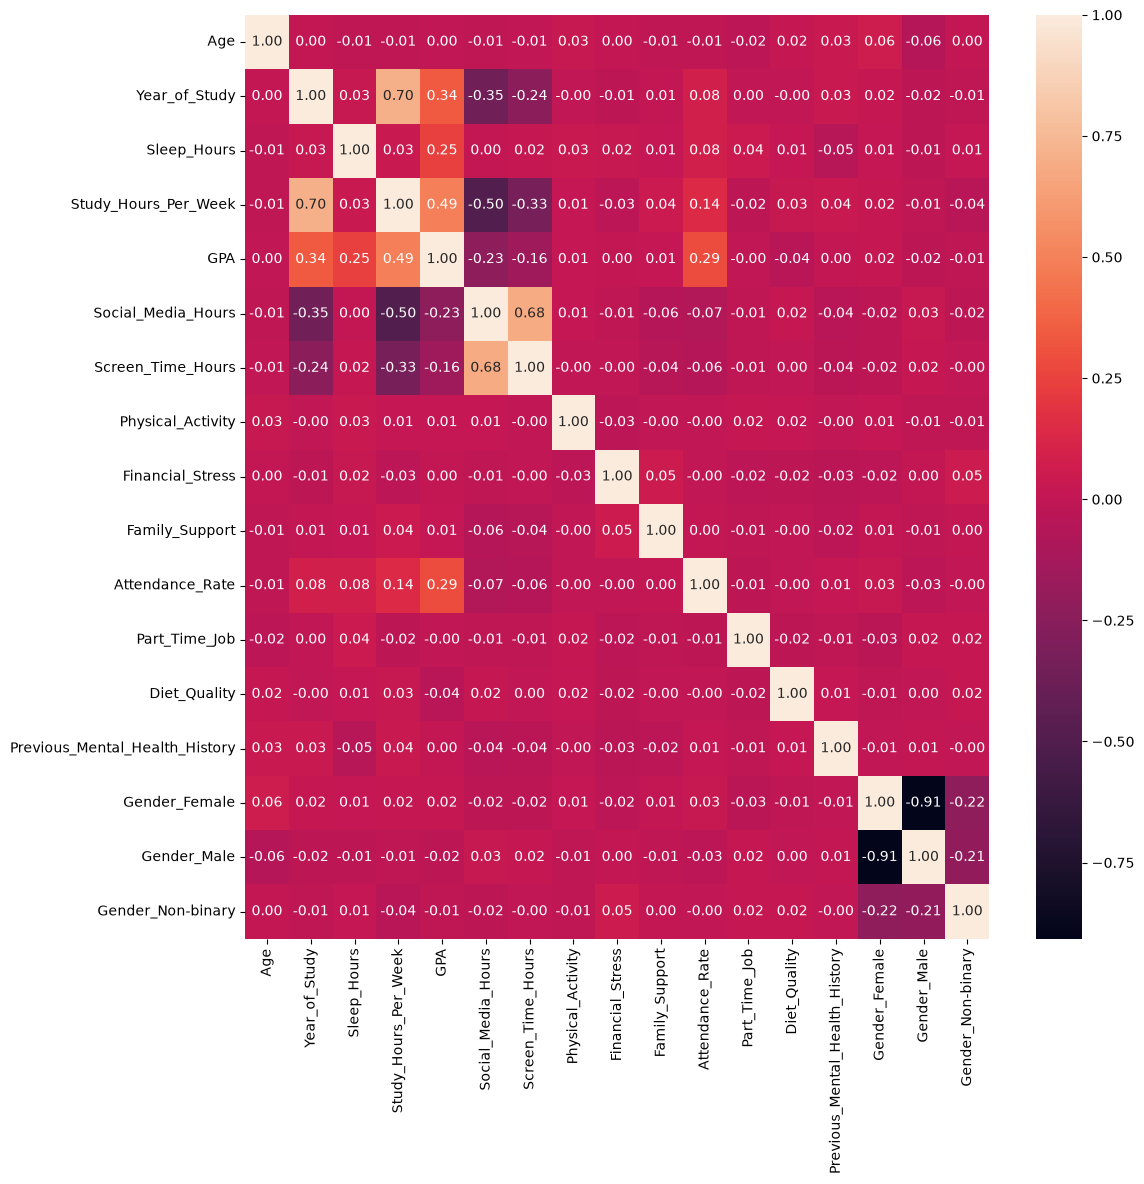

Sleep_Hours                       0.541857
GPA                               0.352626
Financial_Stress                  0.313547
Family_Support                    0.250894
Previous_Mental_Health_History    0.242328
Study_Hours_Per_Week              0.238793
Physical_Activity                 0.231154
Social_Media_Hours                0.207601
Screen_Time_Hours                 0.173972
Year_of_Study                     0.166404
Diet_Quality                      0.153059
Attendance_Rate                   0.145362
Part_Time_Job                     0.114722
Gender_Non-binary                 0.019821
Gender_Male                       0.006956
Age                               0.004961
Gender_Female                     0.001577
dtype: float64



------------------- related columns (columns associated with the target) -----------------------------


Sleep_Hours         0.541857
GPA                 0.352626
Financial_Stress    0.313547
dtype: float64

['Sleep_Hours', 'GPA', 'Financial_Stress']



------------------- unrelated columns (columns not associated with the target) -----------------------------


Family_Support                    0.250894
Previous_Mental_Health_History    0.242328
Study_Hours_Per_Week              0.238793
Physical_Activity                 0.231154
Social_Media_Hours                0.207601
Screen_Time_Hours                 0.173972
Year_of_Study                     0.166404
Diet_Quality                      0.153059
Attendance_Rate                   0.145362
Part_Time_Job                     0.114722
Gender_Non-binary                 0.019821
Gender_Male                       0.006956
Age                               0.004961
Gender_Female                     0.001577
dtype: float64

['Family_Support',
 'Previous_Mental_Health_History',
 'Study_Hours_Per_Week',
 'Physical_Activity',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Year_of_Study',
 'Diet_Quality',
 'Attendance_Rate',
 'Part_Time_Job',
 'Gender_Non-binary',
 'Gender_Male',
 'Age',
 'Gender_Female']

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Gender_Female,Gender_Male,Gender_Non-binary
0,22,3,6.6,17.6,2.91,6.9,7.5,1,8.5,4.0,78.0,1,0.0,1,0,1,0
1,21,4,5.6,22.4,2.92,7.6,11.5,0,4.5,5.3,85.4,0,1.0,1,0,1,0
2,22,5,7.1,28.1,2.68,6.5,8.9,0,4.8,6.1,79.5,1,1.0,1,0,1,0
3,24,1,4.5,14.8,2.23,5.5,7.6,2,3.7,8.0,73.9,1,1.0,0,0,1,0
4,20,1,6.7,17.2,2.69,4.3,7.0,1,8.0,7.4,99.8,0,NaN,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,23,2,7.5,20.3,1.89,7.3,10.7,2,8.2,6.3,80.9,1,1.0,1,0,1,0
1996,21,2,6.4,16.8,2.14,4.6,5.8,1,4.6,3.5,76.9,0,0.0,1,0,1,0
1997,19,1,4.5,13.1,2.54,7.5,10.0,0,6.7,8.1,87.9,0,NaN,1,1,0,0
1998,21,3,8.1,22.3,2.62,4.5,6.6,1,6.5,8.4,100.0,1,2.0,1,0,1,0


In [17]:
copy, crr , related, unrelated = get_numerical_corr_with_target(df)

display(crr)
print()
print()
print("------------------- related columns (columns associated with the target) -----------------------------")
display(related)
display(list(related.index))
print()
print()
print("------------------- unrelated columns (columns not associated with the target) -----------------------------")
display(unrelated)
display(list(unrelated.index))
display(copy)

# Etape 2 & 3

In [18]:
x_train, x_test, y_train, y_test = split_data_stractified(*get_X_Y(df))
x_train, y_train, x_test = preprocess_data(x_train, y_train, x_test)
models, params = get_models_with_params()
grids = {name: train_grid_search(x_train, y_train, model, params[name]) for name, model in models.items()}
grids_summary = summarize_grids(grids)


In [19]:
grids_summary.sort_values(by=['recall', 'f1'], ascending=False)

,accuracy,precision,recall,f1,best_params,pipe
LogisticRegression,0.750000,0.751696,0.749525,0.749870,"{'model__C': 100, 'model__class_weight': None,...","Pipeline(steps=[('preprocessing',\n ..."
RandomForestClassifier,0.681875,0.680205,0.681001,0.679432,"{'model__max_depth': 20, 'model__max_features'...","Pipeline(steps=[('preprocessing',\n ..."
DecisionTreeClassifier,0.585000,0.586851,0.583928,0.582738,"{'model__criterion': 'gini', 'model__max_depth...","Pipeline(steps=[('preprocessing',\n ..."


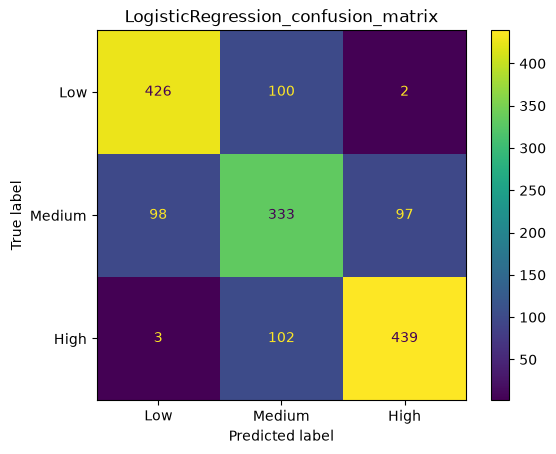

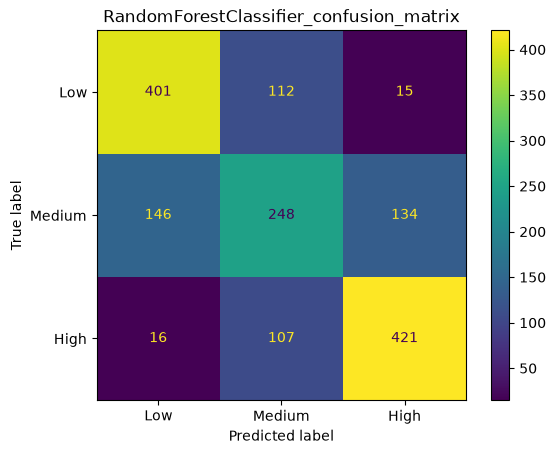

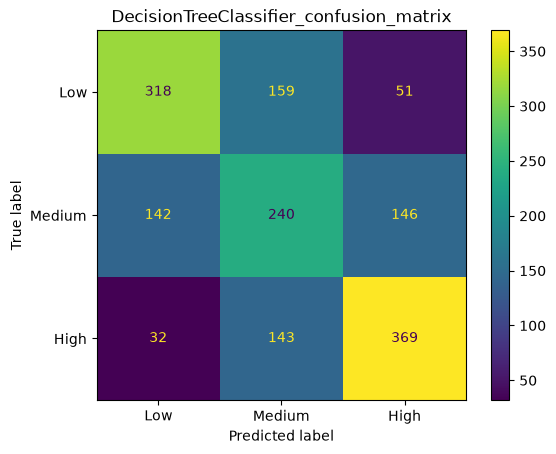

In [20]:
from sklearn import pipeline
from sklearn.metrics import ConfusionMatrixDisplay

from brief_croise_1.config.conf import TARGET_LABELS
from brief_croise_1.train import train_bare_model, train_cross_val_bare_model

models , params = get_models_with_params()
bare_results = {}
for name , model in models.items():
    # res = train_bare_model(x_train, y_train, model)
    res, score = train_cross_val_bare_model(x_train, y_train, model)
    bare_results[name] = res
    ConfusionMatrixDisplay(res['cm'], display_labels=TARGET_LABELS).plot()
    plt.title(f"{name}_confusion_matrix")
    plt.show()
    

best = pd.DataFrame.from_dict(bare_results, orient="index").iloc[0]

In [35]:
pd.DataFrame.from_dict(score)


,fit_time,score_time,test_accuracy,test_precision,test_recall,test_f1
0,0.023268,0.011894,0.562500,0.563288,0.561670,0.562058
1,0.024802,0.011719,0.550000,0.551920,0.549108,0.550087
2,0.023670,0.011689,0.606250,0.604725,0.605405,0.604999
3,0.023634,0.011935,0.550000,0.566862,0.548925,0.553875
4,0.022422,0.011516,0.553125,0.556977,0.552529,0.554097


In [22]:
bare_results = pd.DataFrame.from_dict(bare_results)

In [37]:
bare_results.T

,accuracy,precision,recall,f1,cm
LogisticRegression,0.74875,0.749963,0.748232,0.748328,"[[426, 100, 2], [98, 333, 97], [3, 102, 439]]"
RandomForestClassifier,0.684375,0.678199,0.683344,0.67935,"[[401, 112, 15], [146, 248, 134], [16, 107, 421]]"
DecisionTreeClassifier,0.564375,0.568755,0.563527,0.565023,"[[318, 159, 51], [142, 240, 146], [32, 143, 369]]"


In [23]:
bare_results.T.sort_values(by='f1', ascending=False)

,accuracy,precision,recall,f1,cm
LogisticRegression,0.74875,0.749963,0.748232,0.748328,"[[426, 100, 2], [98, 333, 97], [3, 102, 439]]"
RandomForestClassifier,0.684375,0.678199,0.683344,0.67935,"[[401, 112, 15], [146, 248, 134], [16, 107, 421]]"
DecisionTreeClassifier,0.564375,0.568755,0.563527,0.565023,"[[318, 159, 51], [142, 240, 146], [32, 143, 369]]"


In [24]:
bare_results

,LogisticRegression,RandomForestClassifier,DecisionTreeClassifier
accuracy,0.74875,0.684375,0.564375
precision,0.749963,0.678199,0.568755
recall,0.748232,0.683344,0.563527
f1,0.748328,0.67935,0.565023
cm,"[[426, 100, 2], [98, 333, 97], [3, 102, 439]]","[[401, 112, 15], [146, 248, 134], [16, 107, 421]]","[[318, 159, 51], [142, 240, 146], [32, 143, 369]]"


In [25]:
from sklearn.metrics import classification_report

from brief_croise_1.config.conf import SCORING

name = bare_results.T.iloc[0].name

grid = train_grid_search(x_train, y_train, models[name], params[name])
row = {}
row[name] = {metric: grid.cv_results_[f'mean_test_{metric}'][grid.best_index_] for metric in SCORING}
row[name]['best_params'] = grid.best_params_
row[name]['pipe'] = grid.best_estimator_

best_tuned = pd.DataFrame.from_dict(row, orient="index")

In [26]:
res = classification_report(y_test, grid.best_estimator_.predict(x_test), output_dict=True)

In [ ]:
pd.DataFrame.from_dict(res).T

{'High': {'precision': 0.8161764705882353,
  'recall': 0.8161764705882353,
  'f1-score': 0.8161764705882353,
  'support': 136.0},
 'Low': {'precision': 0.8217054263565892,
  'recall': 0.803030303030303,
  'f1-score': 0.8122605363984674,
  'support': 132.0},
 'Medium': {'precision': 0.6296296296296297,
  'recall': 0.6439393939393939,
  'f1-score': 0.6367041198501873,
  'support': 132.0},
 'accuracy': 0.755,
 'macro avg': {'precision': 0.755837175524818,
  'recall': 0.7543820558526441,
  'f1-score': 0.7550470422789634,
  'support': 400.0},
 'weighted avg': {'precision': 0.7564405684754522,
  'recall': 0.755,
  'f1-score': 0.7556583365620559,
  'support': 400.0}}

In [28]:
best_tuned.iloc[0]

accuracy                                                    0.75
precision                                               0.751696
recall                                                  0.749525
f1                                                       0.74987
best_params    {'model__C': 100, 'model__class_weight': None,...
pipe           Pipeline(steps=[('preprocessing',\n           ...
Name: LogisticRegression, dtype: object

In [29]:
bare_results.T.iloc[0]

accuracy                                           0.74875
precision                                         0.749963
recall                                            0.748232
f1                                                0.748328
cm           [[426, 100, 2], [98, 333, 97], [3, 102, 439]]
Name: LogisticRegression, dtype: object

In [30]:
comparason = pd.DataFrame.from_records([best_tuned.iloc[0], bare_results.T.iloc[0]], index=["tuned", "bare"])
comparason.drop(columns=['best_params', 'pipe', "cm"])

,accuracy,precision,recall,f1
tuned,0.75000,0.751696,0.749525,0.749870
bare,0.74875,0.749963,0.748232,0.748328


In [31]:
_, params = get_models_with_params()
params

{'LogisticRegression': {'C': [0.01, 0.1, 1, 10, 100, 1000],
  'max_iter': [1000, 2000],
  'class_weight': [None, 'balanced'],
  'random_state': [42]},
 'RandomForestClassifier': {'n_estimators': [100, 300, 500],
  'max_depth': [None, 10, 20],
  'min_samples_leaf': [1, 2, 3, 5],
  'max_features': ['sqrt', 0.5],
  'random_state': [42]},
 'DecisionTreeClassifier': {'max_depth': [3, 5, 7, 10, 15, None],
  'min_samples_leaf': [1, 5, 10, 20, 50],
  'criterion': ['gini', 'entropy'],
  'random_state': [42]}}